# Rede Neural Convolucional no MNIST original

Neste notebook eu **baixo a base MNIST a partir dos arquivos originais** (formato IDX, publicados por LeCun, Cortes e Burges), faço a leitura e o pré-processamento manualmente e treino uma **rede neural convolucional (CNN)** com PyTorch. Não uso nenhum carregador pronto (`keras.datasets.mnist`, `torchvision.datasets.MNIST` etc.).

**Roteiro**

1. Download dos arquivos originais
2. Leitura do formato IDX
3. Análise exploratória
4. Pré-processamento
5. Arquitetura da CNN
6. Treinamento
7. Avaliação no conjunto de teste
8. O que a rede aprendeu: filtros e mapas de ativação
9. Conclusões

In [1]:
import copy
import gzip
import hashlib
import math
import struct
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

SEMENTE = 0
np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)
dispositivo = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams['figure.dpi'] = 100
print(f'PyTorch {torch.__version__} | dispositivo: {dispositivo}')

PyTorch 2.14.1+cpu | dispositivo: cpu


## 1. Download dos arquivos originais

A base MNIST é distribuída em 4 arquivos compactados com gzip:

| Arquivo | Conteúdo |
|---|---|
| `train-images-idx3-ubyte.gz` | 60.000 imagens de treino (28×28) |
| `train-labels-idx1-ubyte.gz` | 60.000 rótulos de treino |
| `t10k-images-idx3-ubyte.gz` | 10.000 imagens de teste |
| `t10k-labels-idx1-ubyte.gz` | 10.000 rótulos de teste |

O endereço original é http://yann.lecun.com/exdb/mnist/, mas atualmente ele costuma ficar fora do ar ou bloquear downloads diretos. Por isso, a função abaixo tenta primeiro o site original e, se não conseguir, usa espelhos públicos que hospedam **exatamente os mesmos arquivos** (o espelho do S3 é o mesmo usado internamente pelo PyTorch). Para garantir que os arquivos são os originais e não foram corrompidos, o hash MD5 de cada um é conferido com o valor publicado.

In [2]:
FONTES = [
    'http://yann.lecun.com/exdb/mnist/',                    # site original
    'https://ossci-datasets.s3.amazonaws.com/mnist/',       # espelho (S3)
    'https://storage.googleapis.com/cvdf-datasets/mnist/',  # espelho (Google Cloud Storage)
]
ARQUIVOS_MD5 = {
    'train-images-idx3-ubyte.gz': 'f68b3c2dcbeaaa9fbdd348bbdeb94873',
    'train-labels-idx1-ubyte.gz': 'd53e105ee54ea40749a09fcbcd1e9432',
    't10k-images-idx3-ubyte.gz':  '9fb629c4189551a2d022fa330f9573f3',
    't10k-labels-idx1-ubyte.gz':  'ec29112dd5afa0611ce80d1b7f02629c',
}
PASTA_DADOS = Path('dados/mnist')
PASTA_DADOS.mkdir(parents=True, exist_ok=True)


def baixar(nome, md5_esperado):
    destino = PASTA_DADOS / nome
    if destino.exists() and hashlib.md5(destino.read_bytes()).hexdigest() == md5_esperado:
        print(f'{nome}: já baixado')
        return
    for fonte in FONTES:
        try:
            requisicao = urllib.request.Request(fonte + nome, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(requisicao, timeout=60) as resposta:
                conteudo = resposta.read()
        except Exception as erro:
            print(f'{nome}: falha em {fonte} ({erro})')
            continue
        if hashlib.md5(conteudo).hexdigest() != md5_esperado:
            print(f'{nome}: MD5 não confere em {fonte}, tentando a próxima fonte')
            continue
        destino.write_bytes(conteudo)
        print(f'{nome}: baixado de {fonte} ({len(conteudo) / 1e6:.1f} MB, MD5 ok)')
        return
    raise RuntimeError(f'Não foi possível baixar {nome} de nenhuma fonte.')


for nome, md5 in ARQUIVOS_MD5.items():
    baixar(nome, md5)

train-images-idx3-ubyte.gz: falha em http://yann.lecun.com/exdb/mnist/ (HTTP Error 404: Not Found)


train-images-idx3-ubyte.gz: baixado de https://ossci-datasets.s3.amazonaws.com/mnist/ (9.9 MB, MD5 ok)


train-labels-idx1-ubyte.gz: falha em http://yann.lecun.com/exdb/mnist/ (HTTP Error 404: Not Found)


train-labels-idx1-ubyte.gz: baixado de https://ossci-datasets.s3.amazonaws.com/mnist/ (0.0 MB, MD5 ok)


t10k-images-idx3-ubyte.gz: falha em http://yann.lecun.com/exdb/mnist/ (HTTP Error 404: Not Found)


t10k-images-idx3-ubyte.gz: baixado de https://ossci-datasets.s3.amazonaws.com/mnist/ (1.6 MB, MD5 ok)


t10k-labels-idx1-ubyte.gz: falha em http://yann.lecun.com/exdb/mnist/ (HTTP Error 404: Not Found)


t10k-labels-idx1-ubyte.gz: baixado de https://ossci-datasets.s3.amazonaws.com/mnist/ (0.0 MB, MD5 ok)


## 2. Leitura do formato IDX

Os arquivos estão no formato binário **IDX**, descrito na página original do MNIST. Todos os inteiros do cabeçalho são de 32 bits, *big-endian*:

| Bytes | Conteúdo |
|---|---|
| 0–1 | sempre `0x0000` |
| 2 | tipo dos dados (`0x08` = `unsigned byte`, `0x09` = `signed byte`, `0x0B` = `short`, `0x0C` = `int`, `0x0D` = `float`, `0x0E` = `double`) |
| 3 | número de dimensões $d$ (3 para imagens, 1 para rótulos) |
| 4 … 4+4d | tamanho de cada dimensão |
| restante | os dados, em ordem *row-major* |

Por exemplo, o cabeçalho do arquivo de imagens de treino é `00 00 08 03 | 00 00 EA 60 | 00 00 00 1C | 00 00 00 1C`: tipo `unsigned byte`, 3 dimensões, 60000 × 28 × 28.

In [3]:
TIPOS_IDX = {0x08: np.uint8, 0x09: np.int8, 0x0B: '>i2', 0x0C: '>i4', 0x0D: '>f4', 0x0E: '>f8'}


def ler_idx(caminho):
    """Lê um arquivo IDX (compactado com gzip) e devolve um array NumPy."""
    with gzip.open(caminho, 'rb') as f:
        conteudo = f.read()
    zeros, tipo, n_dim = struct.unpack('>HBB', conteudo[:4])
    if zeros != 0 or tipo not in TIPOS_IDX:
        raise ValueError(f'{caminho} não é um arquivo IDX válido.')
    forma = struct.unpack(f'>{n_dim}I', conteudo[4:4 + 4 * n_dim])
    dados = np.frombuffer(conteudo, dtype=np.dtype(TIPOS_IDX[tipo]), offset=4 + 4 * n_dim)
    if dados.size != np.prod(forma):
        raise ValueError(f'{caminho}: esperados {np.prod(forma)} valores, encontrados {dados.size}.')
    return dados.reshape(forma)


with gzip.open(PASTA_DADOS / 'train-images-idx3-ubyte.gz', 'rb') as f:
    print('Cabeçalho de train-images:', f.read(16).hex(' '))

X_treino_bruto = ler_idx(PASTA_DADOS / 'train-images-idx3-ubyte.gz')
y_treino_bruto = ler_idx(PASTA_DADOS / 'train-labels-idx1-ubyte.gz')
X_teste_bruto = ler_idx(PASTA_DADOS / 't10k-images-idx3-ubyte.gz')
y_teste_bruto = ler_idx(PASTA_DADOS / 't10k-labels-idx1-ubyte.gz')

for nome, arr in [('X_treino', X_treino_bruto), ('y_treino', y_treino_bruto), ('X_teste', X_teste_bruto), ('y_teste', y_teste_bruto)]:
    print(f'{nome:<9} forma={str(arr.shape):<16} tipo={arr.dtype}  mín={arr.min()}  máx={arr.max()}')

Cabeçalho de train-images: 00 00 08 03 00 00 ea 60 00 00 00 1c 00 00 00 1c


X_treino  forma=(60000, 28, 28)  tipo=uint8  mín=0  máx=255
y_treino  forma=(60000,)         tipo=uint8  mín=0  máx=9
X_teste   forma=(10000, 28, 28)  tipo=uint8  mín=0  máx=255
y_teste   forma=(10000,)         tipo=uint8  mín=0  máx=9


## 3. Análise exploratória

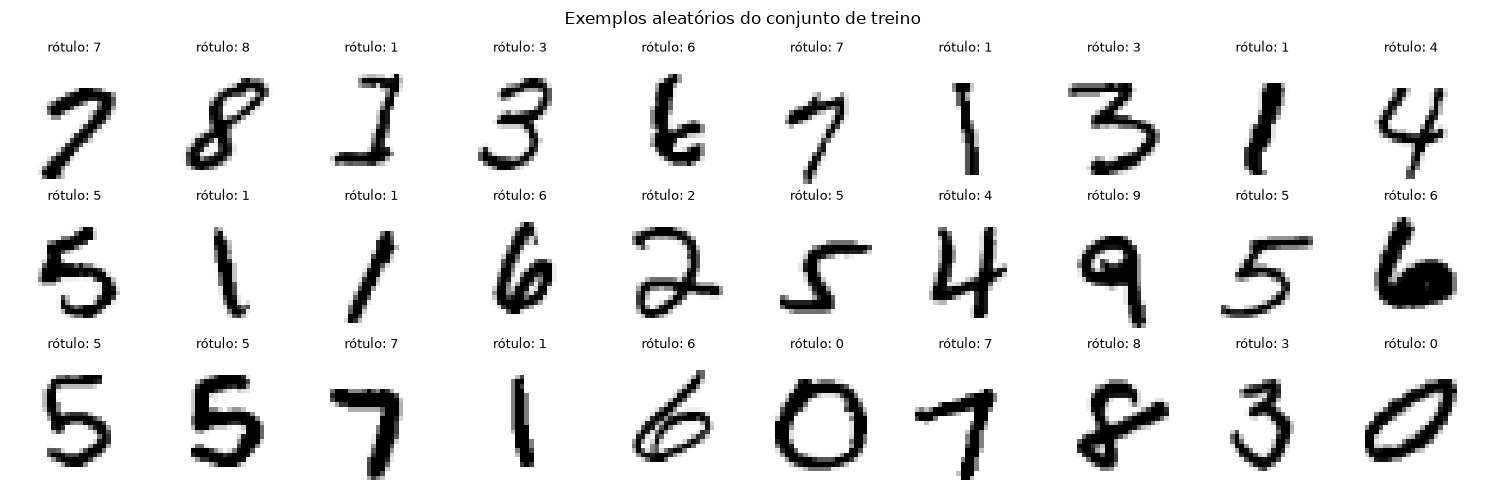

In [4]:
fig, eixos = plt.subplots(3, 10, figsize=(15, 5))
for ax, i in zip(eixos.ravel(), np.random.default_rng(1).choice(len(X_treino_bruto), 30, replace=False)):
    ax.imshow(X_treino_bruto[i], cmap='gray_r')
    ax.set_title(f'rótulo: {y_treino_bruto[i]}', fontsize=9)
    ax.axis('off')
plt.suptitle('Exemplos aleatórios do conjunto de treino')
plt.tight_layout()
plt.show()

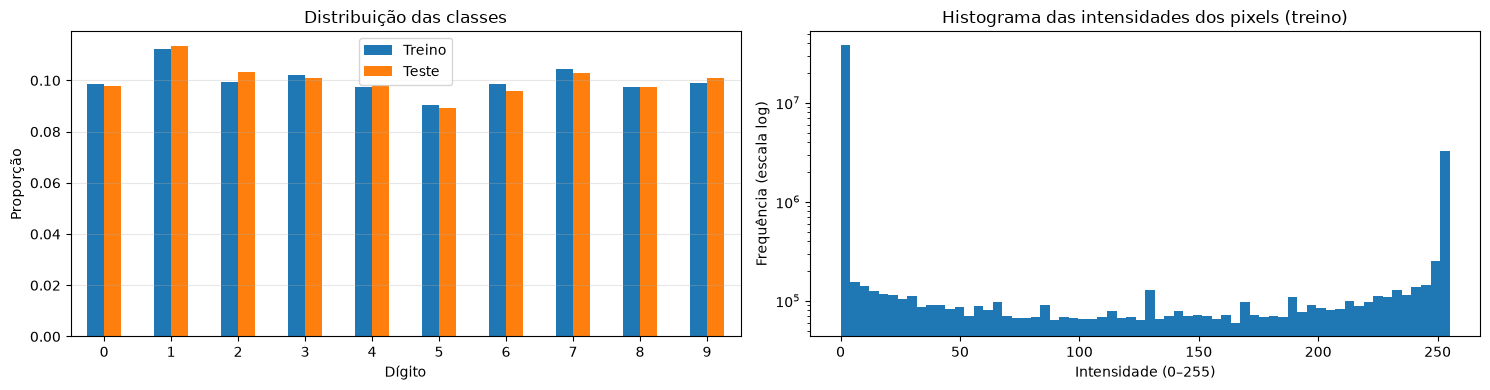

Pixels com valor 0: 80.9%


In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 4))

contagem = pd.DataFrame({
    'Treino': np.bincount(y_treino_bruto, minlength=10) / len(y_treino_bruto),
    'Teste': np.bincount(y_teste_bruto, minlength=10) / len(y_teste_bruto),
})
contagem.plot.bar(ax=eixos[0], rot=0)
eixos[0].set(title='Distribuição das classes', xlabel='Dígito', ylabel='Proporção')
eixos[0].grid(axis='y', alpha=0.3)

eixos[1].hist(X_treino_bruto.ravel(), bins=64, log=True)
eixos[1].set(title='Histograma das intensidades dos pixels (treino)', xlabel='Intensidade (0–255)', ylabel='Frequência (escala log)')
plt.tight_layout()
plt.show()

print(f'Pixels com valor 0: {np.mean(X_treino_bruto == 0):.1%}')

As classes são aproximadamente balanceadas (cada dígito representa entre 9% e 11% das amostras), então a acurácia é uma métrica adequada. A maior parte dos pixels é fundo (valor 0), e o traço do dígito fica concentrado perto de 255.

A imagem média de cada dígito mostra o "formato típico" de cada classe e a variabilidade da escrita:

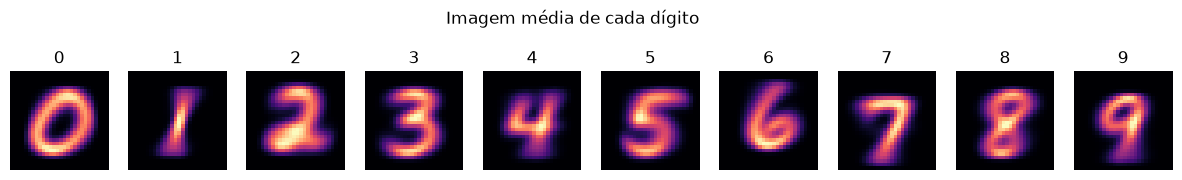

In [6]:
fig, eixos = plt.subplots(1, 10, figsize=(15, 2))
for digito, ax in enumerate(eixos):
    ax.imshow(X_treino_bruto[y_treino_bruto == digito].mean(axis=0), cmap='magma')
    ax.set_title(str(digito))
    ax.axis('off')
plt.suptitle('Imagem média de cada dígito', y=1.05)
plt.show()

## 4. Pré-processamento

1. **Conversão de tipo e escala**: os pixels passam de `uint8` (0–255) para `float32` no intervalo $[0, 1]$.
2. **Dimensão de canal**: camadas convolucionais esperam tensores no formato $(N, C, H, W)$; como as imagens são em tons de cinza, $C = 1$, ficando $(N, 1, 28, 28)$.
3. **Separação de validação**: o conjunto de treino original (60.000 imagens) é dividido em 54.000 para treino e 6.000 para validação, de forma estratificada. A validação é usada para acompanhar o treinamento e escolher a melhor época; o **conjunto de teste original (10.000 imagens) só é usado na avaliação final**.
4. **Padronização**: subtraio a média e divido pelo desvio padrão dos pixels, calculados **apenas no conjunto de treino** (para não vazar informação da validação/teste). Essa operação é feita como primeira camada da rede (módulo `Padronizacao`), assim o modelo recebe imagens em $[0,1]$ e o aumento de dados abaixo pode trabalhar com o fundo preto (0).
5. **Aumento de dados** (só no treino): a cada lote, cada imagem recebe uma transformação afim aleatória — rotação de até ±10°, escala entre 0,9 e 1,1 e deslocamento de até ±2 pixels. Isso simula variações naturais da escrita e reduz o sobreajuste.

In [7]:
# 1 e 2: float32 em [0, 1] com dimensão de canal
X_treino_completo = (X_treino_bruto.astype(np.float32) / 255.0)[:, None, :, :]
X_teste = (X_teste_bruto.astype(np.float32) / 255.0)[:, None, :, :]
y_treino_completo = y_treino_bruto.astype(np.int64)
y_teste = y_teste_bruto.astype(np.int64)

# 3: separação treino / validação estratificada
X_treino, X_val, y_treino, y_val = train_test_split(
    X_treino_completo, y_treino_completo, test_size=6000, stratify=y_treino_completo, random_state=SEMENTE)

# 4: estatísticas para a padronização (apenas treino)
MEDIA, DESVIO = float(X_treino.mean()), float(X_treino.std())

print(f'Treino:    {X_treino.shape}  {X_treino.dtype}')
print(f'Validação: {X_val.shape}')
print(f'Teste:     {X_teste.shape}')
print(f'Média dos pixels (treino) = {MEDIA:.4f} | desvio padrão = {DESVIO:.4f}')

TAMANHO_LOTE = 128
gerador = torch.Generator().manual_seed(SEMENTE)
carregador_treino = DataLoader(TensorDataset(torch.from_numpy(X_treino), torch.from_numpy(y_treino)),
                               batch_size=TAMANHO_LOTE, shuffle=True, generator=gerador)
carregador_val = DataLoader(TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val)), batch_size=1000)
carregador_teste = DataLoader(TensorDataset(torch.from_numpy(X_teste), torch.from_numpy(y_teste)), batch_size=1000)

Treino:    (54000, 1, 28, 28)  float32
Validação: (6000, 1, 28, 28)
Teste:     (10000, 1, 28, 28)
Média dos pixels (treino) = 0.1306 | desvio padrão = 0.3080


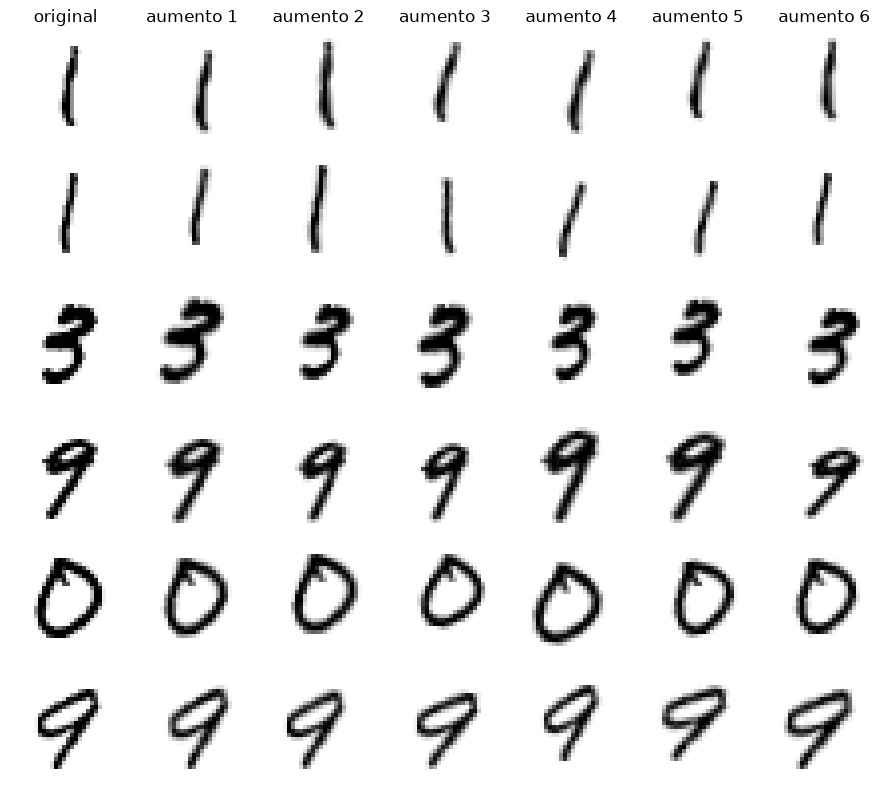

In [8]:
# 5: aumento de dados com transformações afins aleatórias
def aumentar(x, rotacao_max=10, escala=(0.9, 1.1), deslocamento_max=2):
    n = x.shape[0]
    angulo = torch.empty(n, device=x.device).uniform_(-rotacao_max, rotacao_max) * math.pi / 180
    s = torch.empty(n, device=x.device).uniform_(*escala)
    # o affine_grid usa coordenadas normalizadas em [-1, 1]: 1 pixel = 2/28
    desloc = torch.empty(n, 2, device=x.device).uniform_(-deslocamento_max, deslocamento_max) * 2 / x.shape[-1]
    cos, sen = torch.cos(angulo) / s, torch.sin(angulo) / s
    theta = torch.stack([torch.stack([cos, -sen, desloc[:, 0]], dim=1),
                         torch.stack([sen, cos, desloc[:, 1]], dim=1)], dim=1)
    grade = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grade, align_corners=False, padding_mode='zeros')


exemplos = torch.from_numpy(X_treino[:6])
fig, eixos = plt.subplots(6, 7, figsize=(9, 8))
for linha, img in enumerate(exemplos):
    eixos[linha, 0].imshow(img[0], cmap='gray_r')
    versoes = aumentar(img[None].repeat(6, 1, 1, 1))
    for coluna, v in enumerate(versoes, start=1):
        eixos[linha, coluna].imshow(v[0], cmap='gray_r')
for ax in eixos.ravel():
    ax.axis('off')
eixos[0, 0].set_title('original')
for coluna in range(1, 7):
    eixos[0, coluna].set_title(f'aumento {coluna}')
plt.tight_layout()
plt.show()

## 5. Arquitetura da CNN

A rede tem dois blocos convolucionais seguidos de um classificador totalmente conectado:

| Etapa | Camadas | Saída |
|---|---|---|
| Entrada | imagem em tons de cinza | 1 × 28 × 28 |
| Padronização | $(x - \mu)/\sigma$ | 1 × 28 × 28 |
| Bloco 1 | Conv 3×3 (32 filtros) → BatchNorm → ReLU → MaxPool 2×2 | 32 × 14 × 14 |
| Bloco 2 | Conv 3×3 (64 filtros) → BatchNorm → ReLU → MaxPool 2×2 | 64 × 7 × 7 |
| Classificador | Flatten → Dropout(0,3) → Densa(128) → ReLU → Dropout(0,3) → Densa(10) | 10 |

- As **convoluções** aprendem filtros locais (bordas, curvas, traços) e compartilham os pesos por toda a imagem, o que dá invariância a translação e usa bem menos parâmetros que uma camada densa.
- O **max pooling** reduz a resolução pela metade, aumentando o campo receptivo das camadas seguintes.
- **Batch normalization** estabiliza e acelera o treinamento; **dropout** reduz o sobreajuste.
- A saída tem 10 neurônios (um por dígito). O softmax fica embutido na função de perda (`cross_entropy`).

Para mostrar o ganho das camadas convolucionais, também treino uma **MLP** (só camadas densas), com até um pouco mais de parâmetros que a CNN, usando exatamente o mesmo pré-processamento, aumento de dados e procedimento de treino.

In [9]:
class Padronizacao(nn.Module):
    def __init__(self, media, desvio):
        super().__init__()
        self.register_buffer('media', torch.tensor(media))
        self.register_buffer('desvio', torch.tensor(desvio))

    def forward(self, x):
        return (x - self.media) / self.desvio


def criar_cnn():
    return nn.Sequential(
        Padronizacao(MEDIA, DESVIO),
        nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Dropout(0.3), nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
        nn.Dropout(0.3), nn.Linear(128, 10),
    )


def criar_mlp():
    return nn.Sequential(
        Padronizacao(MEDIA, DESVIO),
        nn.Flatten(),
        nn.Linear(28 * 28, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(512, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(256, 10),
    )


def nome_camada(camada):
    if isinstance(camada, nn.Conv2d):
        return f'Conv2d {camada.in_channels}→{camada.out_channels}, filtro {camada.kernel_size[0]}×{camada.kernel_size[1]}'
    if isinstance(camada, nn.Linear):
        return f'Linear (densa) {camada.in_features}→{camada.out_features}'
    if isinstance(camada, nn.MaxPool2d):
        return f'MaxPool2d {camada.kernel_size}×{camada.kernel_size}'
    if isinstance(camada, nn.Dropout):
        return f'Dropout p={camada.p}'
    return camada.__class__.__name__


def resumo(modelo):
    x = torch.zeros(2, 1, 28, 28)
    linhas = []
    modelo.eval()
    with torch.no_grad():
        for camada in modelo:
            x = camada(x)
            linhas.append({'Camada': nome_camada(camada),
                           'Saída': tuple(x.shape[1:]),
                           'Parâmetros': sum(p.numel() for p in camada.parameters())})
    tabela = pd.DataFrame(linhas)
    print(f"Total de parâmetros treináveis: {tabela['Parâmetros'].sum():,}".replace(',', '.'))
    return tabela


resumo(criar_cnn())

Total de parâmetros treináveis: 421.834


,Camada,Saída,Parâmetros
0,Padronizacao,"(1, 28, 28)",0
1,"Conv2d 1→32, filtro 3×3","(32, 28, 28)",320
2,BatchNorm2d,"(32, 28, 28)",64
3,ReLU,"(32, 28, 28)",0
4,MaxPool2d 2×2,"(32, 14, 14)",0
5,"Conv2d 32→64, filtro 3×3","(64, 14, 14)",18496
6,BatchNorm2d,"(64, 14, 14)",128
7,ReLU,"(64, 14, 14)",0
8,MaxPool2d 2×2,"(64, 7, 7)",0
9,Flatten,"(3136,)",0


In [10]:
resumo(criar_mlp())

Total de parâmetros treináveis: 537.354


,Camada,Saída,Parâmetros
0,Padronizacao,"(1, 28, 28)",0
1,Flatten,"(784,)",0
2,Linear (densa) 784→512,"(512,)",401920
3,BatchNorm1d,"(512,)",1024
4,ReLU,"(512,)",0
5,Dropout p=0.3,"(512,)",0
6,Linear (densa) 512→256,"(256,)",131328
7,BatchNorm1d,"(256,)",512
8,ReLU,"(256,)",0
9,Dropout p=0.3,"(256,)",0


## 6. Treinamento

- Função de perda: entropia cruzada.
- Otimizador: Adam, com a política de taxa de aprendizado *one-cycle* (sobe até `3e-3` e depois decai), que costuma convergir bem em poucas épocas.
- Lotes de 128 imagens, 12 épocas.
- Ao fim de cada época o modelo é avaliado na validação, e os pesos da época com **maior acurácia de validação** são mantidos.

Observação: a acurácia de treino exibida é calculada sobre as imagens aumentadas e com dropout ativo, por isso costuma ficar abaixo da acurácia de validação.

In [11]:
EPOCAS = 12


@torch.no_grad()
def avaliar(modelo, carregador):
    modelo.eval()
    perda_total, probabilidades = 0.0, []
    for x, y in carregador:
        x, y = x.to(dispositivo), y.to(dispositivo)
        saida = modelo(x)
        perda_total += F.cross_entropy(saida, y, reduction='sum').item()
        probabilidades.append(F.softmax(saida, dim=1).cpu())
    probabilidades = torch.cat(probabilidades).numpy()
    rotulos = carregador.dataset.tensors[1].numpy()
    predicoes = probabilidades.argmax(axis=1)
    return perda_total / len(rotulos), np.mean(predicoes == rotulos), probabilidades


def treinar(modelo, epocas=EPOCAS, lr_max=3e-3, aumentar_dados=True):
    modelo.to(dispositivo)
    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr_max)
    agendador = torch.optim.lr_scheduler.OneCycleLR(otimizador, max_lr=lr_max, epochs=epocas,
                                                    steps_per_epoch=len(carregador_treino))
    historico = {'perda_treino': [], 'acc_treino': [], 'perda_val': [], 'acc_val': []}
    melhor_acc, melhor_estado = -1, None
    inicio = time.perf_counter()

    for epoca in range(1, epocas + 1):
        modelo.train()
        perda_total, acertos = 0.0, 0
        for x, y in carregador_treino:
            x, y = x.to(dispositivo), y.to(dispositivo)
            if aumentar_dados:
                x = aumentar(x)
            saida = modelo(x)
            perda = F.cross_entropy(saida, y)
            otimizador.zero_grad()
            perda.backward()
            otimizador.step()
            agendador.step()
            perda_total += perda.item() * len(y)
            acertos += (saida.argmax(dim=1) == y).sum().item()

        n = len(carregador_treino.dataset)
        perda_val, acc_val, _ = avaliar(modelo, carregador_val)
        for chave, valor in zip(historico, [perda_total / n, acertos / n, perda_val, acc_val]):
            historico[chave].append(valor)
        if acc_val > melhor_acc:
            melhor_acc, melhor_estado, melhor_epoca = acc_val, copy.deepcopy(modelo.state_dict()), epoca
        print(f'Época {epoca:2d}/{epocas} | treino: perda {perda_total / n:.4f}, acc {acertos / n:.4f} | '
              f'validação: perda {perda_val:.4f}, acc {acc_val:.4f} | {time.perf_counter() - inicio:5.0f} s')

    modelo.load_state_dict(melhor_estado)
    historico['tempo'] = time.perf_counter() - inicio
    historico['melhor_epoca'] = melhor_epoca
    print(f'Melhor época: {melhor_epoca} (acurácia de validação {melhor_acc:.4f})')
    return historico


torch.manual_seed(SEMENTE)
cnn = criar_cnn()
historico_cnn = treinar(cnn)

Época  1/12 | treino: perda 0.5285, acc 0.8375 | validação: perda 0.0746, acc 0.9762 |    43 s


Época  2/12 | treino: perda 0.1638, acc 0.9486 | validação: perda 0.0589, acc 0.9810 |    78 s


Época  3/12 | treino: perda 0.1304, acc 0.9596 | validação: perda 0.0489, acc 0.9860 |   118 s


Época  4/12 | treino: perda 0.1102, acc 0.9660 | validação: perda 0.0461, acc 0.9848 |   154 s


Época  5/12 | treino: perda 0.0859, acc 0.9735 | validação: perda 0.0224, acc 0.9920 |   189 s


...

Época  8/12 | treino: perda 0.0504, acc 0.9845 | validação: perda 0.0177, acc 0.9942 |   293 s


Época  9/12 | treino: perda 0.0436, acc 0.9862 | validação: perda 0.0201, acc 0.9942 |   326 s


Época 10/12 | treino: perda 0.0400, acc 0.9878 | validação: perda 0.0159, acc 0.9947 |   360 s


Época 11/12 | treino: perda 0.0348, acc 0.9896 | validação: perda 0.0161, acc 0.9952 |   397 s


Época 12/12 | treino: perda 0.0320, acc 0.9904 | validação: perda 0.0157, acc 0.9950 |   433 s
Melhor época: 11 (acurácia de validação 0.9952)


In [12]:
torch.manual_seed(SEMENTE)
mlp = criar_mlp()
historico_mlp = treinar(mlp)

Época  1/12 | treino: perda 0.8187, acc 0.7643 | validação: perda 0.1829, acc 0.9540 |     8 s


Época  2/12 | treino: perda 0.3017, acc 0.9074 | validação: perda 0.1077, acc 0.9677 |    13 s


Época  3/12 | treino: perda 0.2366, acc 0.9263 | validação: perda 0.0793, acc 0.9748 |    18 s


Época  4/12 | treino: perda 0.1995, acc 0.9378 | validação: perda 0.0751, acc 0.9755 |    21 s


Época  5/12 | treino: perda 0.1676, acc 0.9477 | validação: perda 0.0600, acc 0.9808 |    25 s


...

Época  8/12 | treino: perda 0.1172, acc 0.9636 | validação: perda 0.0443, acc 0.9847 |    36 s


Época  9/12 | treino: perda 0.1059, acc 0.9670 | validação: perda 0.0408, acc 0.9870 |    40 s


Época 10/12 | treino: perda 0.0940, acc 0.9711 | validação: perda 0.0354, acc 0.9878 |    46 s


Época 11/12 | treino: perda 0.0874, acc 0.9732 | validação: perda 0.0336, acc 0.9888 |    50 s


Época 12/12 | treino: perda 0.0870, acc 0.9733 | validação: perda 0.0334, acc 0.9892 |    54 s
Melhor época: 12 (acurácia de validação 0.9892)


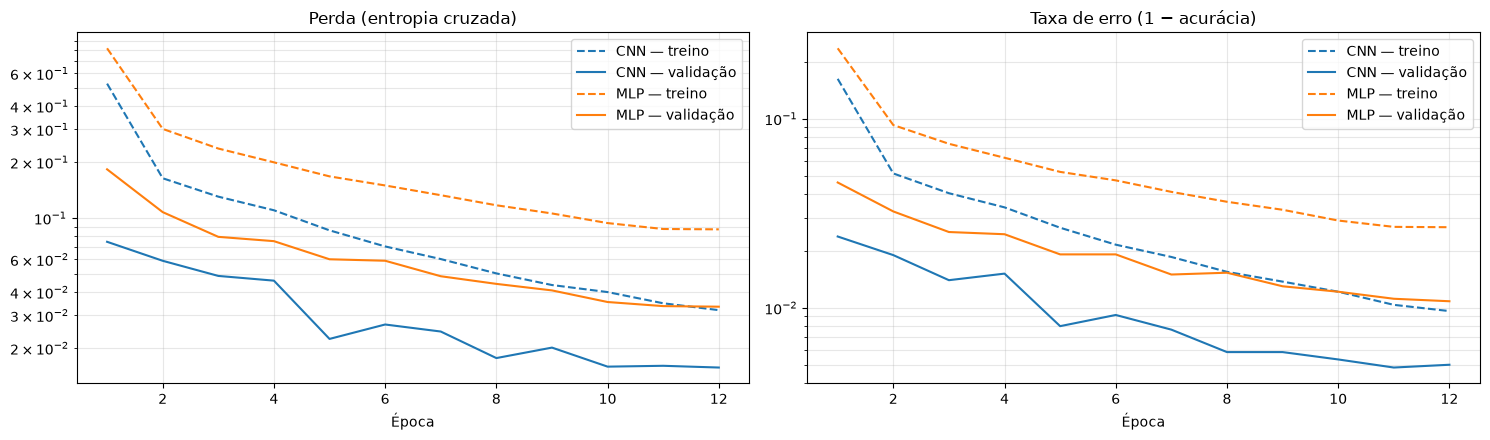

In [13]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 4.5))
for nome, hist, cor in [('CNN', historico_cnn, 'C0'), ('MLP', historico_mlp, 'C1')]:
    epocas = range(1, len(hist['perda_val']) + 1)
    eixos[0].plot(epocas, hist['perda_treino'], '--', color=cor, label=f'{nome} — treino')
    eixos[0].plot(epocas, hist['perda_val'], '-', color=cor, label=f'{nome} — validação')
    eixos[1].plot(epocas, 1 - np.array(hist['acc_treino']), '--', color=cor, label=f'{nome} — treino')
    eixos[1].plot(epocas, 1 - np.array(hist['acc_val']), '-', color=cor, label=f'{nome} — validação')
eixos[0].set(title='Perda (entropia cruzada)', xlabel='Época', yscale='log')
eixos[1].set(title='Taxa de erro (1 − acurácia)', xlabel='Época', yscale='log')
for ax in eixos:
    ax.legend()
    ax.grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

## 7. Avaliação no conjunto de teste

O conjunto de teste original (10.000 imagens) não foi usado em nenhuma etapa anterior.

In [14]:
resultados, probs_teste = [], {}
for nome, modelo, hist in [('CNN', cnn, historico_cnn), ('MLP', mlp, historico_mlp)]:
    perda_teste, acc_teste, probs_teste[nome] = avaliar(modelo, carregador_teste)
    resultados.append({
        'Modelo': nome,
        'Parâmetros': sum(p.numel() for p in modelo.parameters()),
        'Acurácia validação': max(hist['acc_val']),
        'Acurácia teste': acc_teste,
        'Erros no teste (de 10.000)': int(round((1 - acc_teste) * len(y_teste))),
        'Tempo de treino (s)': round(hist['tempo']),
    })
pd.DataFrame(resultados).set_index('Modelo').round(4)

,Parâmetros,Acurácia validação,Acurácia teste,Erros no teste (de 10.000),Tempo de treino (s)
Modelo,,,,,
CNN,421834,0.9952,0.9948,52,433
MLP,537354,0.9892,0.9900,100,54


              precision    recall  f1-score   support

           0     0.9969    0.9980    0.9975       980
           1     0.9947    0.9965    0.9956      1135
           2     0.9942    0.9961    0.9952      1032
           3     0.9941    0.9980    0.9960      1010
           4     0.9899    0.9959    0.9929       982
           5     0.9955    0.9933    0.9944       892
           6     0.9969    0.9927    0.9948       958
           7     0.9922    0.9942    0.9932      1028
           8     0.9959    0.9959    0.9959       974
           9     0.9980    0.9871    0.9925      1009

    accuracy                         0.9948     10000
   macro avg     0.9948    0.9948    0.9948     10000
weighted avg     0.9948    0.9948    0.9948     10000



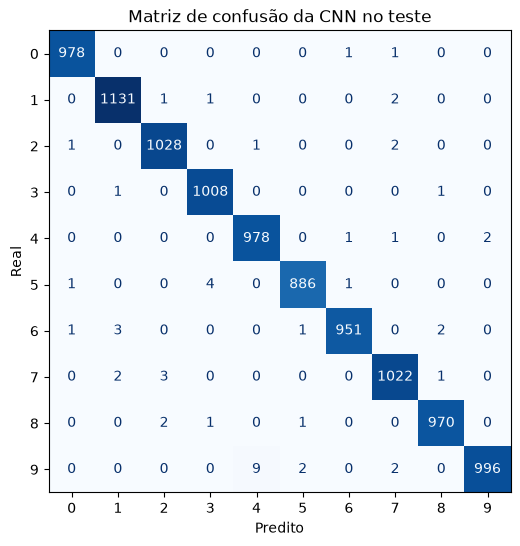

In [15]:
pred_cnn = probs_teste['CNN'].argmax(axis=1)
print(classification_report(y_teste, pred_cnn, digits=4))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_teste, pred_cnn, ax=ax, cmap='Blues', colorbar=False)
ax.set(title='Matriz de confusão da CNN no teste', xlabel='Predito', ylabel='Real')
plt.show()

### Exemplos que a CNN errou

Abaixo estão erros da CNN no teste, com o rótulo real, a predição e a confiança da rede. Muitos deles são ambíguos até para um humano.

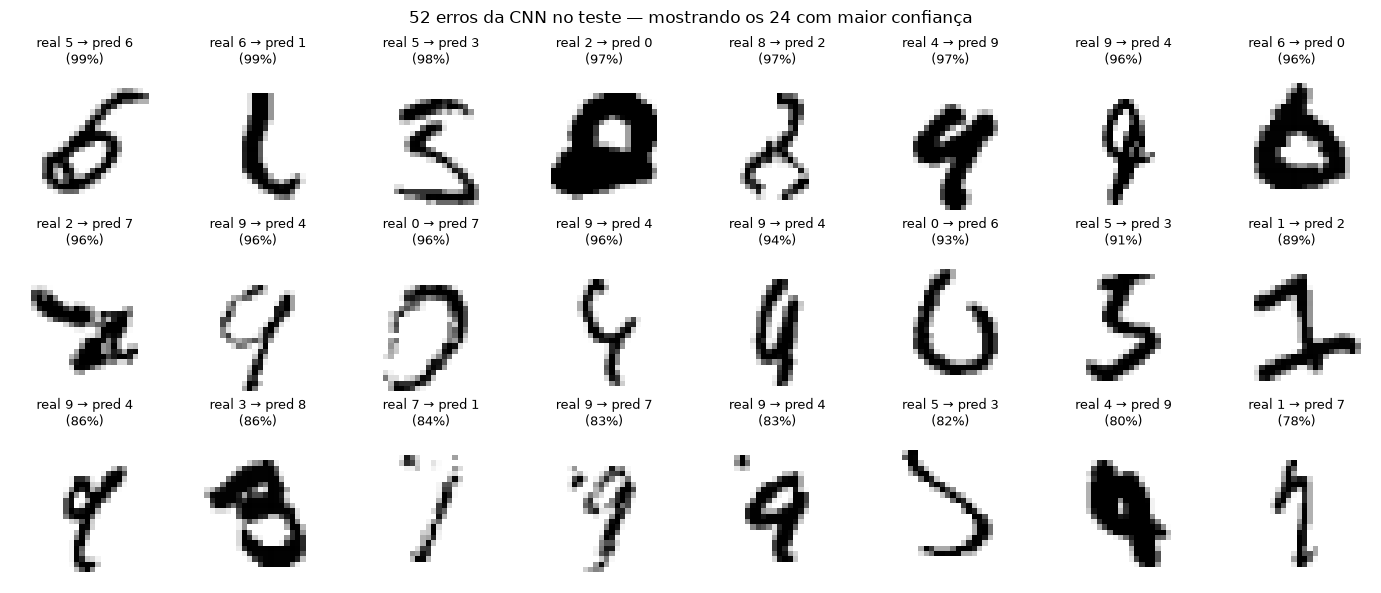

In [16]:
erros = np.flatnonzero(pred_cnn != y_teste)
erros = erros[np.argsort(-probs_teste['CNN'][erros].max(axis=1))]  # mais confiantes primeiro
fig, eixos = plt.subplots(3, 8, figsize=(14, 6))
for ax, i in zip(eixos.ravel(), erros):
    ax.imshow(X_teste[i, 0], cmap='gray_r')
    ax.set_title(f'real {y_teste[i]} → pred {pred_cnn[i]}\n({probs_teste["CNN"][i].max():.0%})', fontsize=9)
    ax.axis('off')
for ax in eixos.ravel()[len(erros):]:
    ax.axis('off')
plt.suptitle(f'{len(erros)} erros da CNN no teste — mostrando os {min(24, len(erros))} com maior confiança')
plt.tight_layout()
plt.show()

## 8. O que a rede aprendeu

### Filtros da primeira camada convolucional

Os 32 filtros 3×3 da primeira camada atuam como detectores de bordas e traços em diferentes orientações.

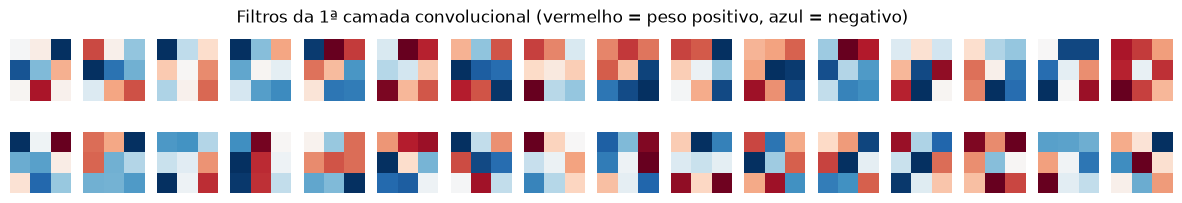

In [17]:
filtros = cnn[1].weight.detach().cpu()[:, 0]
fig, eixos = plt.subplots(2, 16, figsize=(15, 2.2))
for ax, f in zip(eixos.ravel(), filtros):
    limite = f.abs().max()
    ax.imshow(f, cmap='RdBu_r', vmin=-limite, vmax=limite)
    ax.axis('off')
plt.suptitle('Filtros da 1ª camada convolucional (vermelho = peso positivo, azul = negativo)')
plt.show()

### Mapas de ativação

Saída de cada filtro após o primeiro bloco (32 mapas de 14×14) e após o segundo bloco (primeiros 32 de 64 mapas de 7×7) para uma imagem de teste. No primeiro bloco ainda é possível reconhecer o dígito, com diferentes bordas realçadas; no segundo, a representação é mais abstrata e de menor resolução.

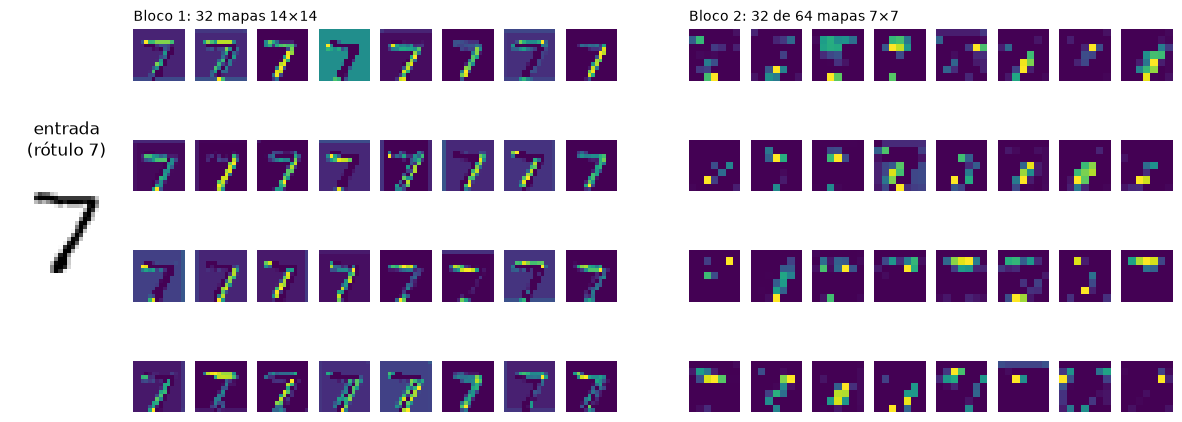

In [18]:
imagem = torch.from_numpy(X_teste[:1]).to(dispositivo)
cnn.eval()
with torch.no_grad():
    bloco1 = cnn[:5](imagem)[0].cpu()
    bloco2 = cnn[:9](imagem)[0].cpu()

fig = plt.figure(figsize=(15, 5.5))
grade = fig.add_gridspec(4, 19)
ax = fig.add_subplot(grade[1:3, 0:2])
ax.imshow(X_teste[0, 0], cmap='gray_r')
ax.set_title(f'entrada\n(rótulo {y_teste[0]})')
ax.axis('off')
for k, (mapas, titulo) in enumerate([(bloco1, 'Bloco 1: 32 mapas 14×14'), (bloco2[:32], 'Bloco 2: 32 de 64 mapas 7×7')]):
    for i, mapa in enumerate(mapas):
        ax = fig.add_subplot(grade[i // 8, 2 + k * 9 + i % 8])
        ax.imshow(mapa, cmap='viridis')
        ax.axis('off')
        if i == 0:
            ax.set_title(titulo, loc='left', fontsize=10)
plt.show()

## 9. Conclusões

- **Dados**: o site original do MNIST (yann.lecun.com) retornou erro 404, então os arquivos foram obtidos de um espelho. O MD5 de todos os 4 arquivos conferiu com os valores publicados, garantindo que são os arquivos originais. A leitura do formato IDX foi feita manualmente a partir do cabeçalho binário.
- **Pré-processamento**: conversão para `float32` em $[0,1]$, inclusão da dimensão de canal, separação estratificada de 6.000 imagens para validação, padronização com média e desvio do treino ($\mu \approx 0{,}1306$, $\sigma \approx 0{,}3080$) e aumento de dados com transformações afins aleatórias.
- **Resultado**: a CNN atingiu **99,48% de acurácia no teste** (52 erros em 10.000 imagens) após 12 épocas, com precisão e revocação acima de 98,7% para todos os dígitos. Os erros que restam são, em boa parte, dígitos mal escritos ou ambíguos até para uma pessoa; as confusões mais comuns são 9↔4 (11 casos), 2↔7 (5), 5→3 (4) e 7↔1 (4), pares com traços parecidos.
- **CNN × MLP**: com o mesmo pré-processamento e procedimento de treino, a MLP chegou a 99,00% (100 erros), tendo **mais** parâmetros (537 mil contra 422 mil). A CNN cometeu cerca de metade dos erros porque as convoluções exploram a estrutura espacial da imagem: os filtros são locais e compartilhados por toda a imagem, o que dá robustez a pequenos deslocamentos e deformações. Na MLP, cada pixel é uma entrada independente e essa estrutura precisa ser aprendida a partir dos dados.
- **Custo**: na CPU, cada época da CNN foi bem mais lenta que a da MLP, porque as convoluções em resolução 28×28 exigem muito mais operações por imagem, apesar do número menor de parâmetros. Com GPU essa diferença diminui bastante.
- **Interpretação**: os filtros da primeira camada se comportam como detectores de bordas em diferentes orientações, e os mapas de ativação mostram que o primeiro bloco ainda preserva a forma do dígito, enquanto o segundo produz uma representação mais abstrata, usada pelo classificador.
- A acurácia de validação ficou acima da de treino durante todo o treinamento. Isso é esperado: no treino as imagens são aumentadas e o dropout fica ativo, o que torna a tarefa mais difícil; na validação, não. Não há sinal de sobreajuste: a perda de validação caiu até a última época.